# 3-09 테마 바스켓 — 키워드로 테마주를 찾고 수익률을 지수와 비교

**질문 예시:** "원전 테마주 최근 3개월 수익률 어때? 코스피보다 나았어?", "로봇 관련주 뭐가 있고 어떤 종목이 끌어올렸어?"

테마 키워드 하나로 ① 관련 상장사를 찾고, ② 그중 **그 테마로 주로 언급되는 종목**(순수도)을 골라 바스켓을 만든 뒤,
③ 바스켓 수익률을 코스피·코스닥과 비교하고 ④ 종목별 기여도를 봅니다.

**왜 DeepSearch로 하나 (신규):** CHECK에는 업종 분류도 문서 태그도 없어 테마 종목을 고를 방법이 없습니다.
DeepSearch는 문서 기반 연관 기업 검색(`FindAssociatedEntity`)과 뉴스 종목 태그 집계(`DocumentAggregation`)로
테마 구성 종목을 데이터로 정합니다.

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/3_price_screener/09_theme_basket.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        if len(docs) < count:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
ASOF = "2026-11-24"
THEMES = ["원전", "로봇"]      # 키워드를 바꿔 보세요 (예: "방산", "2차전지", "조선")
LOOKBACK_MONTHS = 3            # 수익률·뉴스 집계 기간
MIN_MENTIONS = 10              # 기간 중 테마 기사 최소 건수
MIN_PURITY = 0.05              # 그 종목 기사 중 테마 기사 비율 하한
BASKET_SIZE = 12
MAX_WEIGHT = 0.25              # 시총가중 바스켓의 한 종목 비중 상한
# 종목명이 일반 단어와 같아 관련 없는 기사까지 태그되는 종목(동명 오탐). 예: '미래산업'은 3개월 기사 4,244건으로
# 시가총액에 비해 비정상적으로 많고 '미래 산업'이라는 표현에 걸린 기사가 대부분입니다.
EXCLUDE = {"KRX:025560"}       # 미래산업

START = (pd.Timestamp(ASOF) - pd.DateOffset(months=LOOKBACK_MONTHS)).date()
print("기간", START, "~", ASOF)

기간 2026-08-24 ~ 2026-11-24


## 1. 후보 종목: 연관 기업 검색 + 테마 기사 종목 집계
- `FindAssociatedEntity(키워드, N, date_from, date_to)`: 공시·뉴스·리포트를 바탕으로 한 연관도 점수(0~100)
- **순수도** = (테마 키워드가 들어간 그 종목 기사 수) ÷ (그 종목 전체 기사 수). 기사 수는 `DocumentAggregation`으로 전 종목을 한 번에 셉니다.
- **테마 점수** = 테마 기사 수 × 순수도. 기사가 많으면서 그 테마로 주로 언급되는 종목이 위로 옵니다.
  (기사 수만 쓰면 현대차·삼성전자 같은 대형주가, 순수도만 쓰면 기사 몇 건뿐인 소형주가 위로 옵니다.)

In [4]:
def agg_news(query, size=3000):
    df = ds_df(f'DocumentAggregation(["news"],[],{json.dumps(query, ensure_ascii=False)},'
               f'"securities.symbol:{size}",date_from={START},date_to={ASOF})')
    df = df[df["key"].str.fullmatch(r"\d{6}")]
    return df.set_index("KRX:" + df["key"])["count"].astype(float)

all_news = agg_news("*")          # 종목별 전체 기사 수 (테마 공통)
u = universe()
# 일반법인(1)·공기업(2) 보통주. 공기업(한국전력·한전기술 등)은 company_type_l1이 "2"라 "1"만 거르면 빠집니다.
common = u[u["company_type_l1"].isin(["1", "2"]) & u["symbol"].str.endswith("0")].set_index("symbol")

def candidates(theme):
    fae = ds_df(f'FindAssociatedEntity({json.dumps(theme, ensure_ascii=False)}, 40, date_from={START}, date_to={ASOF})')
    fae = fae.set_index("symbol").iloc[:, -1].rename("연관점수")
    theme_news = agg_news(f'"{theme}"', size=300).rename("테마기사")
    c = pd.concat([fae, theme_news], axis=1)
    c = c[c.index.isin(common.index) & ~c.index.isin(EXCLUDE)]
    c["전체기사"] = all_news.reindex(c.index)
    c["순수도"] = c["테마기사"] / c["전체기사"]
    c["테마점수"] = c["테마기사"] * c["순수도"]
    c.insert(0, "name", common.loc[c.index, "name"])
    c.insert(1, "market", common.loc[c.index, "market"])
    return c

cands = {t: candidates(t) for t in THEMES}
for t, c in cands.items():
    print(f"[{t}] 후보 {len(c)}개 (연관검색 {c['연관점수'].notna().sum()}, 테마기사 집계 {c['테마기사'].notna().sum()})")

[원전] 후보 192개 (연관검색 40, 테마기사 집계 191)
[로봇] 후보 294개 (연관검색 39, 테마기사 집계 294)


## 2. 바스켓 구성
테마 기사 `MIN_MENTIONS`건 이상, 순수도 `MIN_PURITY` 이상인 종목을 테마 점수 순으로 `BASKET_SIZE`개 고릅니다.
연관 점수는 높지만 테마 비중이 낮아 빠진 종목도 함께 보여 줍니다.

In [5]:
baskets = {}
for t, c in cands.items():
    ok = c[(c["테마기사"] >= MIN_MENTIONS) & (c["순수도"] >= MIN_PURITY)]
    baskets[t] = ok.sort_values("테마점수", ascending=False).head(BASKET_SIZE)
    dropped = c[c["연관점수"].notna() & ~c.index.isin(baskets[t].index)].sort_values("연관점수", ascending=False).head(5)
    print(f"\n[{t}] 바스켓 {len(baskets[t])}종목 / 연관 점수는 높지만 제외된 예: "
          + ", ".join(f"{r.name_}({r.순수도:.0%})" for r in dropped.rename(columns={"name": "name_"}).itertuples()))

baskets[THEMES[0]][["name", "market", "테마점수", "테마기사", "전체기사", "순수도", "연관점수"]].round(2)


[원전] 바스켓 12종목 / 연관 점수는 높지만 제외된 예: 우진(1%), 세아베스틸지주(5%), GS건설(1%), 효성중공업(0%), 지투파워(40%)

[로봇] 바스켓 12종목 / 연관 점수는 높지만 제외된 예: 현대모비스(9%), 현대위아(26%), 포스코DX(27%), SFA(58%), 마키나락스(17%)


,name,market,테마점수,테마기사,전체기사,순수도,연관점수
KRX:047040,대우건설,KOSPI,53.09,274.0,1414.0,0.19,81.82
KRX:015760,한국전력,KOSPI,30.52,282.0,2606.0,0.11,81.71
KRX:052690,한전기술,KOSPI,29.33,44.0,66.0,0.67,81.15
KRX:034020,두산에너빌리티,KOSPI,17.96,256.0,3650.0,0.07,95.23
KRX:000500,가온전선,KOSPI,12.21,57.0,266.0,0.21,NaN
KRX:000720,현대건설,KOSPI,10.14,153.0,2309.0,0.07,81.49
KRX:051600,한전KPS,KOSPI,7.41,41.0,227.0,0.18,80.82
KRX:454910,두산로보틱스,KOSPI,6.48,28.0,121.0,0.23,NaN
KRX:100840,SNT에너지,KOSPI,6.06,24.0,95.0,0.25,61.97
KRX:028260,삼성물산,KOSPI,4.32,85.0,1673.0,0.05,81.37


In [6]:
baskets[THEMES[1]][["name", "market", "테마점수", "테마기사", "전체기사", "순수도", "연관점수"]].round(2)

,name,market,테마점수,테마기사,전체기사,순수도,연관점수
KRX:005380,현대차,KOSPI,268.75,1576.0,9242.0,0.17,95.40
KRX:066570,LG전자,KOSPI,188.20,808.0,3469.0,0.23,95.33
KRX:108490,로보티즈,KOSDAQ,142.03,159.0,178.0,0.89,81.45
KRX:277810,레인보우로보틱스,KOSDAQ,129.44,137.0,145.0,0.94,62.97
KRX:307180,아이엘,KOSDAQ,78.41,99.0,125.0,0.79,76.30
KRX:035890,서희건설,KOSDAQ,74.19,137.0,253.0,0.54,NaN
KRX:348340,뉴로메카,KOSDAQ,71.00,71.0,71.0,1.00,NaN
KRX:454910,두산로보틱스,KOSPI,68.44,91.0,121.0,0.75,94.42
KRX:377480,마음AI,KOSDAQ,67.85,86.0,109.0,0.79,62.12
KRX:005930,삼성전자,KOSPI,55.03,1017.0,18796.0,0.05,77.27


## 3. 바스켓 수익률 vs 지수
바스켓 종목 시세를 한 번에 받아(`GetStockPrices([종목…])`) 동일가중·시가총액가중 누적수익률을 계산하고 코스피·코스닥과 비교합니다.
둘 다 시작일 비중으로 사고 그대로 두는 방식(리밸런싱 없음)이고, 시총가중은 한 종목 비중을 `MAX_WEIGHT`로 제한합니다.

In [7]:
idx = index_prices(START, ASOF)
idx = idx[idx["symbol"].isin(["KRX:KOSPI", "KRX:KOSDAQ"])].pivot(index="date", columns="entity_name", values="close")
curves = {f"{n} 지수": idx[n] / idx[n].iloc[0] - 1 for n in idx.columns}
contrib = {}

for t, b in baskets.items():
    px = stock_prices(list(b.index), START, ASOF, columns=["close", "market_cap"])
    close = px.pivot(index="date", columns="symbol", values="close").sort_index().ffill()
    mcap0 = px.sort_values("date").groupby("symbol")["market_cap"].first()
    close = close.dropna(axis=1, subset=[close.index[0]])      # 기간 중 상장 종목 제외
    rel = close / close.iloc[0]
    w = mcap0.reindex(rel.columns); w = w / w.sum()
    for _ in range(20):                                         # 비중 상한 적용 후 다시 나눠 맞춤
        over = w > MAX_WEIGHT
        if not over.any():
            break
        w[over] = MAX_WEIGHT
        w[~over] = w[~over] / w[~over].sum() * (1 - MAX_WEIGHT * over.sum())
    curves[f"{t} 동일가중"] = rel.mean(axis=1) - 1
    curves[f"{t} 시총가중"] = (rel * w).sum(axis=1) - 1
    r = rel.iloc[-1] - 1
    contrib[t] = pd.DataFrame({"name": b.loc[r.index, "name"], "수익률(%)": r * 100,
                               "시총비중(%)": w * 100, "시총가중 기여(%p)": r * w * 100}).sort_values("시총가중 기여(%p)", ascending=False)

perf = pd.DataFrame(curves)
print(PRICE_NOTICE)
(perf.iloc[[-1]].T * 100).round(1).rename(columns=lambda c: f"누적수익률(%) {c:%Y-%m-%d}")

※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). 거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).


date,누적수익률(%) 2026-11-24
코스닥 지수,-18.1
코스피 지수,-25.2
원전 동일가중,-22.8
원전 시총가중,-32.8
로봇 동일가중,-20.7
로봇 시총가중,-27.2


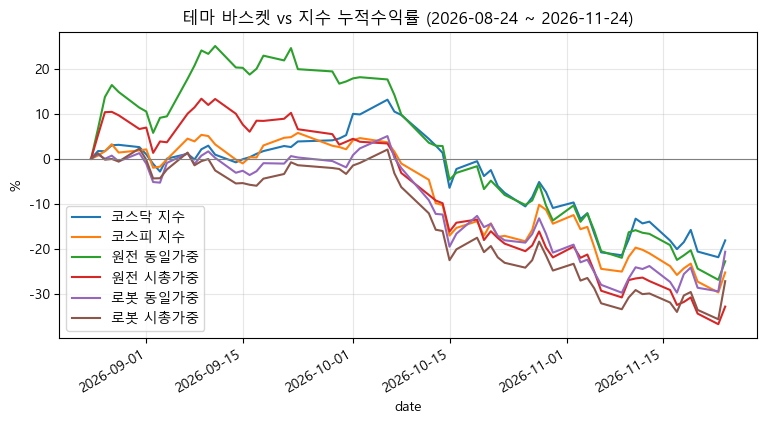

In [8]:
ax = (perf * 100).plot(figsize=(9, 4.5), title=f"테마 바스켓 vs 지수 누적수익률 ({START} ~ {ASOF})")
ax.set_ylabel("%"); ax.axhline(0, color="gray", lw=.8); ax.grid(alpha=.3)

## 4. 종목별 기여도
시총가중 수익률 = Σ(시작 시총 비중 × 종목 수익률). 누가 바스켓을 끌어올렸는지 봅니다.

In [9]:
contrib[THEMES[0]].round(1)

,name,수익률(%),시총비중(%),시총가중 기여(%p)
symbol,,,,
KRX:000500,가온전선,42.9,2.3,1.0
KRX:100840,SNT에너지,-5.1,0.3,-0.0
KRX:051600,한전KPS,-24.0,1.0,-0.2
KRX:375500,DL이앤씨,-33.2,1.3,-0.4
KRX:052690,한전기술,-29.8,1.7,-0.5
KRX:454910,두산로보틱스,-24.1,2.2,-0.5
KRX:047040,대우건설,-33.2,3.2,-1.1
KRX:015760,한국전력,-19.4,10.1,-1.9
KRX:000720,현대건설,-33.9,5.8,-2.0


In [10]:
contrib[THEMES[1]].round(1)

,name,수익률(%),시총비중(%),시총가중 기여(%p)
symbol,,,,
KRX:108490,로보티즈,18.8,2.4,0.4
KRX:277810,레인보우로보틱스,6.2,5.6,0.3
KRX:377480,마음AI,-23.5,0.0,-0.0
KRX:348340,뉴로메카,-18.9,0.2,-0.0
KRX:035890,서희건설,-13.5,0.3,-0.0
KRX:307180,아이엘,-33.7,0.1,-0.0
KRX:454910,두산로보틱스,-24.1,3.0,-0.7
KRX:307950,현대오토에버,-20.8,8.2,-1.7
KRX:011070,LG이노텍,-50.1,8.8,-4.4


## 결과 읽는 법과 한계
- 테마 구성은 **기사 언급 기반**이라 기간을 바꾸면 종목이 달라집니다. 순수도 하한을 낮추면 대형주가 들어오고
  시총가중 수익률이 지수와 비슷해집니다.
- 뉴스 종목 태그에는 동명 종목 오탐(예: 'DB', '미래산업')이 있습니다. 전체 기사 수가 회사 규모에 비해 지나치게 많으면
  기사를 확인하고 `EXCLUDE`에 넣으세요. 다른 회사 이야기에 함께 언급된 계열사(예: 원전 기사 속 두산로보틱스)도 섞일 수 있습니다.
- 현재 상장 종목 기준이라 기간 중 상장폐지된 종목은 빠지고(생존 편향), 기간 중 신규 상장 종목은 수익률 계산에서 제외합니다.
- 가격은 수정주가(배당 미반영)라 총수익률이 아닌 가격수익률입니다.